In [2]:
data_path="/content/data (2).csv"
print("24BAD109 SHAQEEQ S")

24BAD109 SHAQEEQ S


## PART A: Visualization of Activation Functions

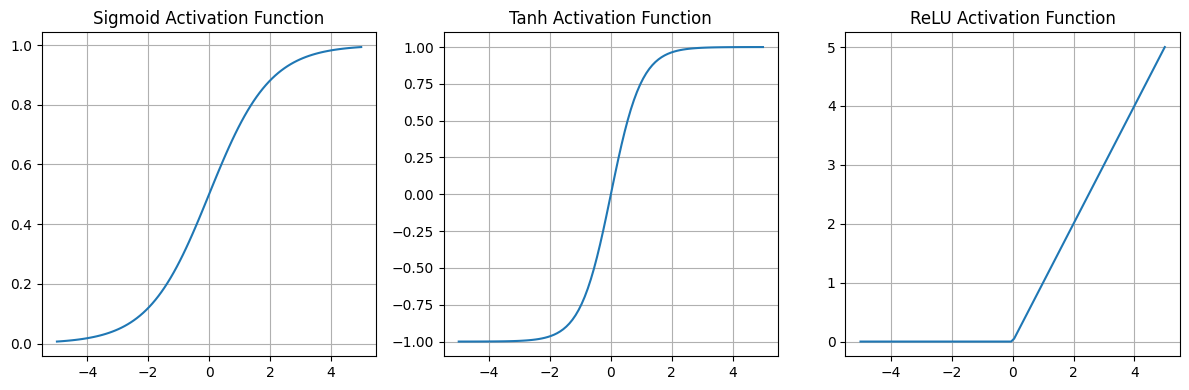

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Sigmoid function
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

# Tanh function
def tanh(x):
    return np.tanh(x)

# ReLU function
def relu(x):
    return np.maximum(0, x)

# Generate a range of x values
x = np.linspace(-5, 5, 100)

# Plot Sigmoid
plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1)
plt.plot(x, sigmoid(x))
plt.title('Sigmoid Activation Function')
plt.grid(True)

# Plot Tanh
plt.subplot(1, 3, 2)
plt.plot(x, tanh(x))
plt.title('Tanh Activation Function')
plt.grid(True)

# Plot ReLU
plt.subplot(1, 3, 3)
plt.plot(x, relu(x))
plt.title('ReLU Activation Function')
plt.grid(True)

plt.tight_layout()
plt.show()

### Comparison of Activation Functions

**Sigmoid:**
*   **Output Range:** (0, 1)
*   **Saturation Regions:** Saturated at very high positive inputs (output close to 1) and very low negative inputs (output close to 0).
*   **Gradient Behavior:** Gradients are very small (close to 0) in the saturation regions, leading to the "vanishing gradient" problem during backpropagation. The strongest gradient is around x=0.
*   **Computational Efficiency:** Involves an exponential calculation, which is computationally more expensive than ReLU.
*   **Typical Applications:** Output layers of binary classification models (e.g., logistic regression), where the output needs to be interpreted as a probability.

**Tanh (Hyperbolic Tangent):**
*   **Output Range:** (-1, 1)
*   **Saturation Regions:** Saturated at very high positive inputs (output close to 1) and very low negative inputs (output close to -1).
*   **Gradient Behavior:** Similar to Sigmoid, suffers from vanishing gradients in saturation regions, but its gradient is stronger and centered around 0, making it generally preferred over Sigmoid for hidden layers. Output is zero-centered, which helps in optimizing the network.
*   **Computational Efficiency:** Also involves exponential calculations, similar to Sigmoid, making it more expensive than ReLU.
*   **Typical Applications:** Hidden layers in neural networks. It often performs better than Sigmoid because its output is zero-centered.

**ReLU (Rectified Linear Unit):**
*   **Output Range:** [0, $\infty$)
*   **Saturation Regions:** Saturated for negative inputs (output is 0). No upper saturation.
*   **Gradient Behavior:** For positive inputs, the gradient is constant (1), preventing vanishing gradients. For negative inputs, the gradient is 0, which can lead to the "dying ReLU" problem where neurons become inactive and stop learning. Much faster computation as it only involves simple thresholding.
*   **Computational Efficiency:** Computationally very efficient as it only requires a simple thresholding operation (max(0, x)).
*   **Typical Applications:** Most common activation function for hidden layers in deep neural networks due to its efficiency and ability to mitigate vanishing gradients.

## PART B: Performance Comparison of Activation Functions

In [4]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import make_classification # For a generic dataset if 'data (2).csv' is not suitable or available
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Load the dataset (assuming 'data_path' points to a classification dataset)
# If 'data (2).csv' is not a suitable classification dataset, we'll generate one.
try:
    df = pd.read_csv(data_path)
    print(f"Successfully loaded data from {data_path}")
    print("First 5 rows of the dataset:")
    display(df.head())
    print("\nDataset info:")
    df.info()

    # Assuming the last column is the target variable for a classification task
    # You might need to adjust this based on your actual 'data (2).csv' content
    if df.shape[1] > 1:
        X = df.iloc[:, :-1]
        y = df.iloc[:, -1]
        # Ensure y is suitable for classification (e.g., binary or multi-class integer labels)
        if not np.issubdtype(y.dtype, np.integer):
            print("\nWarning: Target variable is not integer. Attempting to convert.")
            y = pd.factorize(y)[0]
        if len(np.unique(y)) < 2:
             raise ValueError("Target variable has less than 2 unique classes, not suitable for classification.")
    else:
        raise ValueError("Dataset has only one column, not suitable for X and y split.")

except FileNotFoundError:
    print(f"Error: The file at {data_path} was not found.")
    print("Generating a synthetic classification dataset for demonstration purposes.")
    X, y = make_classification(n_samples=1000, n_features=20, n_classes=2, random_state=42)
    X = pd.DataFrame(X, columns=[f'feature_{i}' for i in range(X.shape[1])])
    y = pd.Series(y, name='target')
    print("Synthetic dataset generated.")
    print("First 5 rows of features (X):")
    display(X.head())
    print("First 5 values of target (y):")
    display(y.head())
except Exception as e:
    print(f"An error occurred while loading or processing the dataset: {e}")
    print("Generating a synthetic classification dataset for demonstration purposes.")
    X, y = make_classification(n_samples=1000, n_features=20, n_classes=2, random_state=42)
    X = pd.DataFrame(X, columns=[f'feature_{i}' for i in range(X.shape[1])])
    y = pd.Series(y, name='target')
    print("Synthetic dataset generated.")
    print("First 5 rows of features (X):")
    display(X.head())
    print("First 5 values of target (y):")
    display(y.head())

# Split data into training and validation sets
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

# Standardize features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

print(f"\nShape of X_train_scaled: {X_train_scaled.shape}")
print(f"Shape of y_train: {y_train.shape}")

Successfully loaded data from /content/data (2).csv
First 5 rows of the dataset:


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN



Dataset info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_s

,feature_0,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,feature_10,feature_11,feature_12,feature_13,feature_14,feature_15,feature_16,feature_17,feature_18,feature_19
0,-0.669356,-1.495778,-0.870766,1.141831,0.021606,1.730630,-1.251698,0.289305,0.357163,-0.196811,0.829274,0.154850,-0.219970,-0.739137,1.802012,1.634606,-0.938180,-1.267337,-1.276334,1.016643
1,0.093372,0.785848,0.105754,1.272354,-0.846316,-0.979093,1.263707,0.264020,2.411677,-0.960046,0.543479,0.199810,0.288724,0.732492,-0.872002,-1.654887,-1.130204,-0.122709,0.693431,0.911363
2,-0.905797,-0.608341,0.295141,0.943716,0.092936,1.370397,-0.064772,0.287273,-0.533004,-0.032504,-0.549925,-0.510064,-0.868768,-0.598279,0.019832,0.613460,-1.779439,0.830498,-0.737332,-0.578212
3,-0.585793,0.389279,0.698816,0.436236,-0.315082,0.459505,1.448820,0.505558,-1.440982,-1.134020,-0.241431,1.466783,0.678728,-1.190917,-1.442381,-0.929136,-0.221600,-0.346772,0.034246,-1.040199
4,1.146441,0.515579,-1.222895,-0.396230,-1.293508,-0.352428,0.071254,1.239584,1.007133,-1.479444,-0.695695,-0.918127,0.604121,1.068379,-0.882271,2.303639,-0.973379,1.259233,0.360015,1.920368


First 5 values of target (y):


,target
0,1
1,0
2,1
3,1
4,0



Shape of X_train_scaled: (800, 20)
Shape of y_train: (800,)


In [5]:
# Function to create a simple ANN model
def create_model(activation_function):
    model = keras.Sequential([
        layers.Input(shape=(X_train_scaled.shape[1],)),
        layers.Dense(64, activation=activation_function, name=f'hidden_layer_1_{activation_function}'),
        layers.Dense(32, activation=activation_function, name=f'hidden_layer_2_{activation_function}'),
        layers.Dense(1, activation='sigmoid', name='output_layer') # For binary classification
    ])
    model.compile(
        optimizer='adam',
        loss='binary_crossentropy',
        metrics=['accuracy']
    )
    return model

# Train and evaluate models for each activation function
activation_functions = ['sigmoid', 'tanh', 'relu']
results = {}

for act_fn in activation_functions:
    print(f"\nTraining model with {act_fn} activation...")
    model = create_model(act_fn)

    # Use EarlyStopping to find convergence
    early_stopping = tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=10, # Number of epochs with no improvement after which training will be stopped.
        restore_best_weights=True
    )

    history = model.fit(
        X_train_scaled, y_train,
        epochs=100, # Max epochs, but EarlyStopping will stop earlier
        batch_size=32,
        validation_data=(X_val_scaled, y_val),
        callbacks=[early_stopping],
        verbose=0 # Suppress verbose output during training
    )

    # Evaluate the model
    loss, accuracy = model.evaluate(X_val_scaled, y_val, verbose=0)
    train_loss = history.history['loss'][-1]
    train_accuracy = history.history['accuracy'][-1]
    epochs_needed = len(history.epoch)

    results[act_fn] = {
        'Training Accuracy': train_accuracy,
        'Validation Accuracy': accuracy,
        'Training Loss': train_loss,
        'Validation Loss': loss,
        'Epochs Required': epochs_needed,
        'History': history
    }
    print(f"Model with {act_fn} activation trained in {epochs_needed} epochs.")

# Display results in a DataFrame
results_df = pd.DataFrame(results).T
print("\nPerformance Comparison of Activation Functions:")
display(results_df.round(4))


Training model with sigmoid activation...
Model with sigmoid activation trained in 34 epochs.

Training model with tanh activation...
Model with tanh activation trained in 15 epochs.

Training model with relu activation...
Model with relu activation trained in 23 epochs.

Performance Comparison of Activation Functions:


,Training Accuracy,Validation Accuracy,Training Loss,Validation Loss,Epochs Required,History
sigmoid,0.88625,0.865,0.304062,0.363265,34,<keras.src.callbacks.history.History object at...
tanh,0.88625,0.875,0.282261,0.356316,15,<keras.src.callbacks.history.History object at...
relu,0.95125,0.87,0.163177,0.360122,23,<keras.src.callbacks.history.History object at...


## PART C: Comparison of Optimization Algorithms


Training model with SGD optimizer...
Model with SGD optimizer trained in 60 epochs.

Training model with Momentum optimizer...
Model with Momentum optimizer trained in 21 epochs.

Training model with RMSProp optimizer...
Model with RMSProp optimizer trained in 19 epochs.

Training model with Adam optimizer...
Model with Adam optimizer trained in 22 epochs.

Performance Comparison of Optimization Algorithms:


,Final Training Accuracy,Final Validation Accuracy,Final Training Loss,Final Validation Loss,Epochs Required
SGD,0.9050,0.850,0.2562,0.3794,60.0
Momentum,0.9463,0.870,0.1679,0.3598,21.0
RMSProp,0.9312,0.840,0.1971,0.3601,19.0
Adam,0.9475,0.865,0.1682,0.3624,22.0


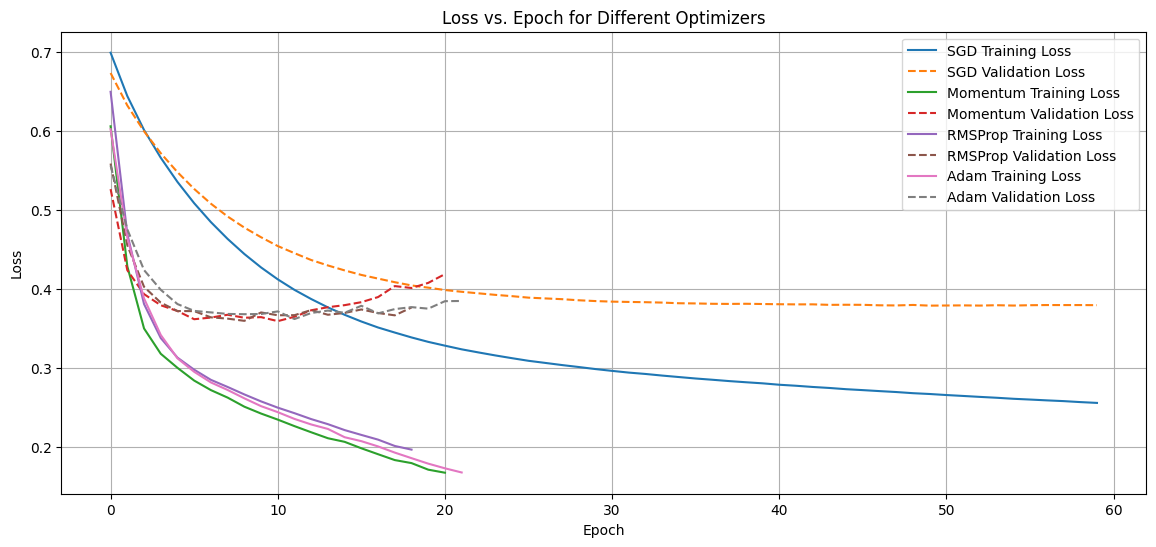

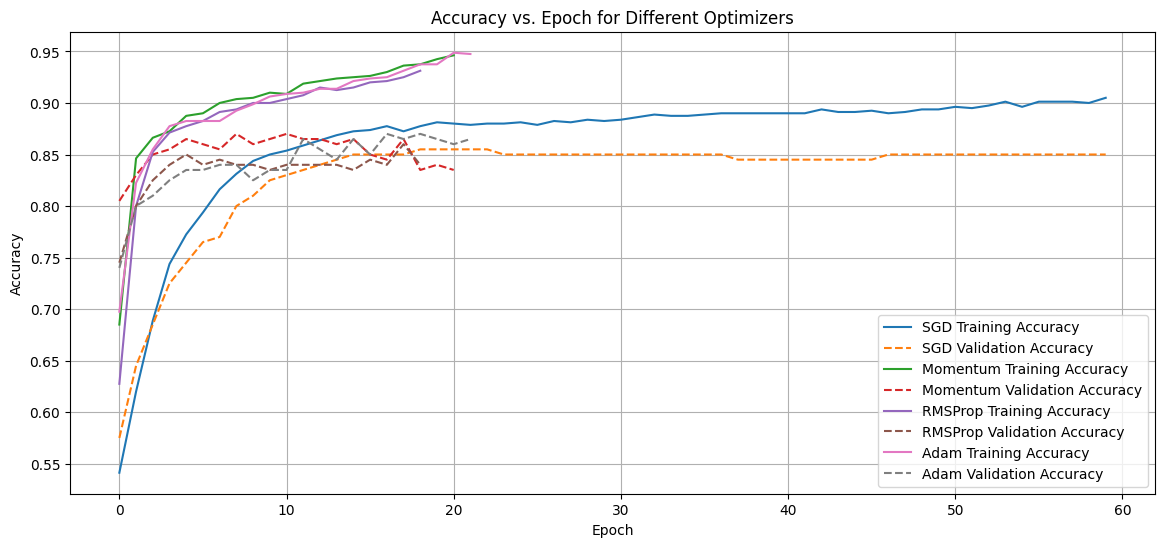

In [6]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt
import pandas as pd

# Define a common ANN architecture (using ReLU as the activation function, as it's often a good default)
def create_common_model(optimizer):
    model = keras.Sequential([
        layers.Input(shape=(X_train_scaled.shape[1],)),
        layers.Dense(64, activation='relu', name='hidden_layer_1'),
        layers.Dense(32, activation='relu', name='hidden_layer_2'),
        layers.Dense(1, activation='sigmoid', name='output_layer') # For binary classification
    ])
    model.compile(
        optimizer=optimizer,
        loss='binary_crossentropy',
        metrics=['accuracy']
    )
    return model

# Define the optimization algorithms to compare
optimizers = {
    'SGD': tf.keras.optimizers.SGD(learning_rate=0.01),
    'Momentum': tf.keras.optimizers.SGD(learning_rate=0.01, momentum=0.9),
    'RMSProp': tf.keras.optimizers.RMSprop(learning_rate=0.001),
    'Adam': tf.keras.optimizers.Adam(learning_rate=0.001)
}

results_optimizers = {}
histories = {}

for opt_name, optimizer_instance in optimizers.items():
    print(f"\nTraining model with {opt_name} optimizer...")
    model = create_common_model(optimizer_instance)

    # Use EarlyStopping for consistent comparison of convergence
    early_stopping = tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=10, # Number of epochs with no improvement after which training will be stopped.
        restore_best_weights=True
    )

    history = model.fit(
        X_train_scaled, y_train,
        epochs=100, # Max epochs
        batch_size=32,
        validation_data=(X_val_scaled, y_val),
        callbacks=[early_stopping],
        verbose=0
    )

    loss, accuracy = model.evaluate(X_val_scaled, y_val, verbose=0)
    train_loss = history.history['loss'][-1]
    train_accuracy = history.history['accuracy'][-1]
    epochs_needed = len(history.epoch)

    results_optimizers[opt_name] = {
        'Final Training Accuracy': train_accuracy,
        'Final Validation Accuracy': accuracy,
        'Final Training Loss': train_loss,
        'Final Validation Loss': loss,
        'Epochs Required': epochs_needed
    }
    histories[opt_name] = history
    print(f"Model with {opt_name} optimizer trained in {epochs_needed} epochs.")

# Display results
results_df_optimizers = pd.DataFrame(results_optimizers).T
print("\nPerformance Comparison of Optimization Algorithms:")
display(results_df_optimizers.round(4))

# Plot Loss vs Epoch
plt.figure(figsize=(14, 6))
for opt_name, history in histories.items():
    plt.plot(history.history['loss'], label=f'{opt_name} Training Loss')
    plt.plot(history.history['val_loss'], label=f'{opt_name} Validation Loss', linestyle='--')
plt.title('Loss vs. Epoch for Different Optimizers')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

# Plot Accuracy vs Epoch
plt.figure(figsize=(14, 6))
for opt_name, history in histories.items():
    plt.plot(history.history['accuracy'], label=f'{opt_name} Training Accuracy')
    plt.plot(history.history['val_accuracy'], label=f'{opt_name} Validation Accuracy', linestyle='--')
plt.title('Accuracy vs. Epoch for Different Optimizers')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()